# Exploratory Data Analysis & Visualization: Titanic Survival Analysis

## Project Overview
This notebook presents a comprehensive Exploratory Data Analysis (EDA) on the Kaggle Titanic dataset (`train.csv`). The primary goal is to analyze the demographic, socioeconomic, and spatial variables that influenced passenger survival outcomes during the Titanic disaster.

---

## Objectives
1. **Data Cleaning & Imputation:** Address missing values in `Age`, `Embarked`, and `Cabin` using stratified medians and mode estimation.
2. **Feature Engineering:** Create domain-specific variables including `FamilySize`, `IsAlone`, and extracted passenger `Title` categories.
3. **Exploratory Analytics:** Investigate survival dynamics across demographic groups, socioeconomic classes, and family structures.
4. **Visual Artifact Generation:** Produce publication-ready visualizations and export them directly to the `report/` directory for final report integration.

---

## Workspace & Directory Structure

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
os.makedirs("report", exist_ok=True)


In [3]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})
df = pd.read_csv("../data/train.csv")
print(f"Dataset Loaded Successfully! Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print(df.info())

Dataset Loaded Successfully! Shape: 891 rows, 12 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


# Handle missing values

In [4]:
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda x: x.fillna(x.median()))
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])


In [5]:

df["Cabin_Known"] = df["Cabin"].notna().astype(int)
df.drop(columns=["Cabin"], inplace=True)
print("Remaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Remaining Missing Values:
Series([], dtype: int64)


In [7]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
rare_titles = ["Lady", "Countess", "Capt", "Col", "Don", "Dr", "Major", "Rev", "Sir", "Jonkheer", "Dona"]
df["Title"] = df["Title"].replace(rare_titles, "Rare")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
print("Engineered Features Preview:")
print(df[["Name", "Title", "FamilySize", "IsAlone", "Cabin_Known"]].head())

Engineered Features Preview:
                                                Name Title  FamilySize  \
0                            Braund, Mr. Owen Harris    Mr           2   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...   Mrs           2   
2                             Heikkinen, Miss. Laina  Miss           1   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)   Mrs           2   
4                           Allen, Mr. William Henry    Mr           1   

   IsAlone  Cabin_Known  
0        0            0  
1        0            1  
2        1            0  
3        0            1  
4        1            0  


## Univariate Analysis

C:\Users\lavan\AppData\Local\Temp\ipykernel_13664\1914254848.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="Survived", palette="Set2")


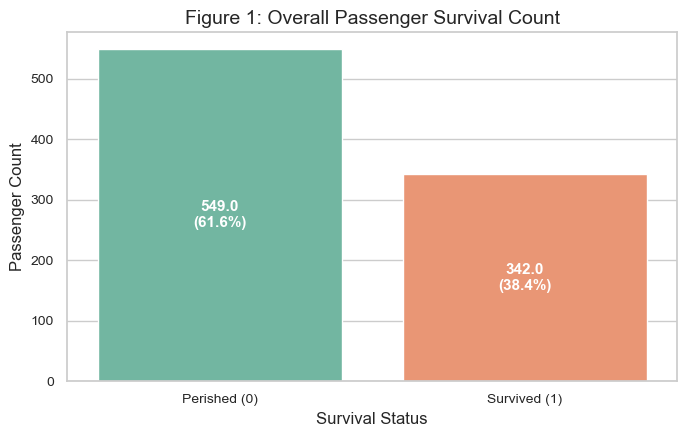

In [8]:
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=df, x="Survived", palette="Set2")
plt.title("Figure 1: Overall Passenger Survival Count")
plt.xlabel("Survival Status")
plt.ylabel("Passenger Count")
plt.xticks([0, 1], ["Perished (0)", "Survived (1)"])
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f"{(height/total)*100:.1f}%"
    ax.annotate(f"{height}\n({percentage})", 
                (p.get_x() + p.get_width() / 2., height / 2),
                ha="center", va="center", color="white", fontweight="bold")
plt.tight_layout()
plt.savefig("report/fig1_survival_count.png", dpi=300)
plt.show()

## Bivariate Analysis

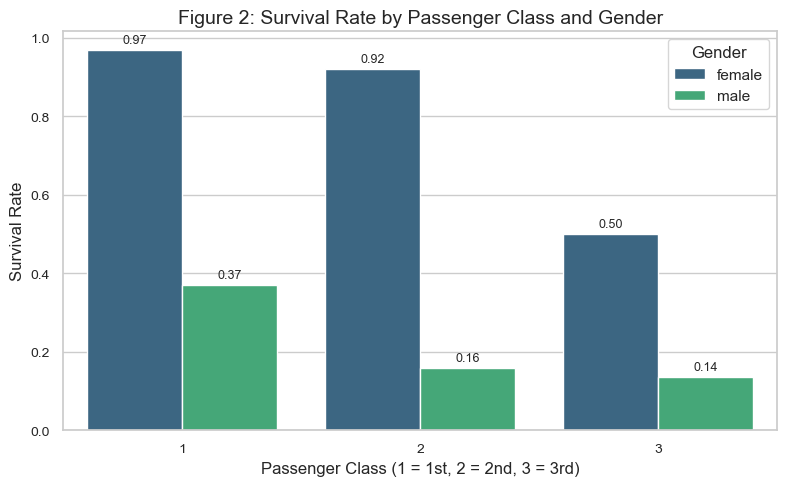

C:\Users\lavan\AppData\Local\Temp\ipykernel_13664\1522996205.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="FamilySize", y="Survived", palette="magma", errorbar=None)


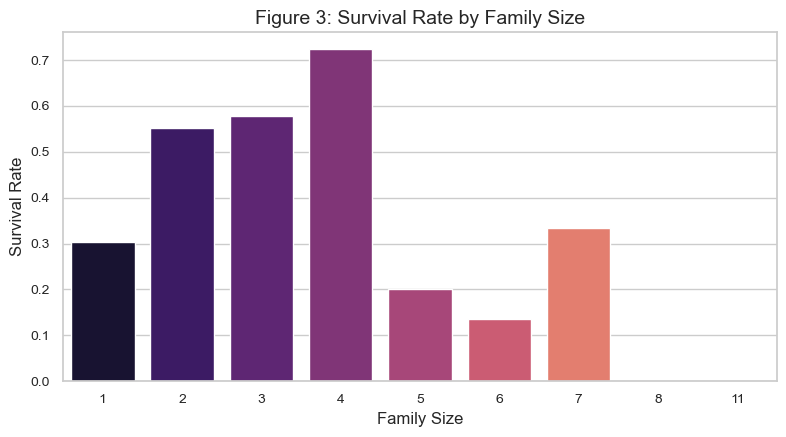

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None, palette="viridis")
plt.title("Figure 2: Survival Rate by Passenger Class and Gender")
plt.xlabel("Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)")
plt.ylabel("Survival Rate")
plt.legend(title="Gender", loc="upper right")
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f"{height:.2f}", 
                            (p.get_x() + p.get_width() / 2., height),
                            ha="center", va="bottom", xytext=(0, 3), 
                            textcoords="offset points", fontsize=9)
plt.tight_layout()
plt.savefig("report/fig2_survival_pclass_sex.png", dpi=300)
plt.show()


C:\Users\lavan\AppData\Local\Temp\ipykernel_13664\2466098357.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="FamilySize", y="Survived", palette="magma", errorbar=None)


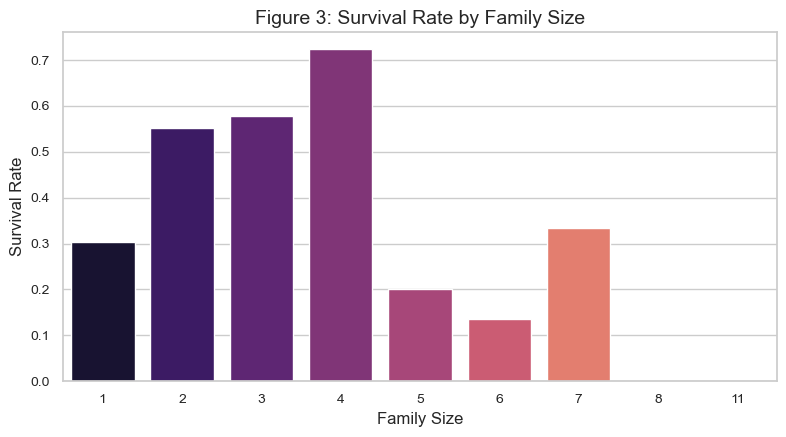

In [13]:
plt.figure(figsize=(8, 4.5))
sns.barplot(data=df, x="FamilySize", y="Survived", palette="magma", errorbar=None)
plt.title("Figure 3: Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.savefig("report/fig3_survival_familysize.png", dpi=300)
plt.show()

## Continuous Distributions & KDE Analytics

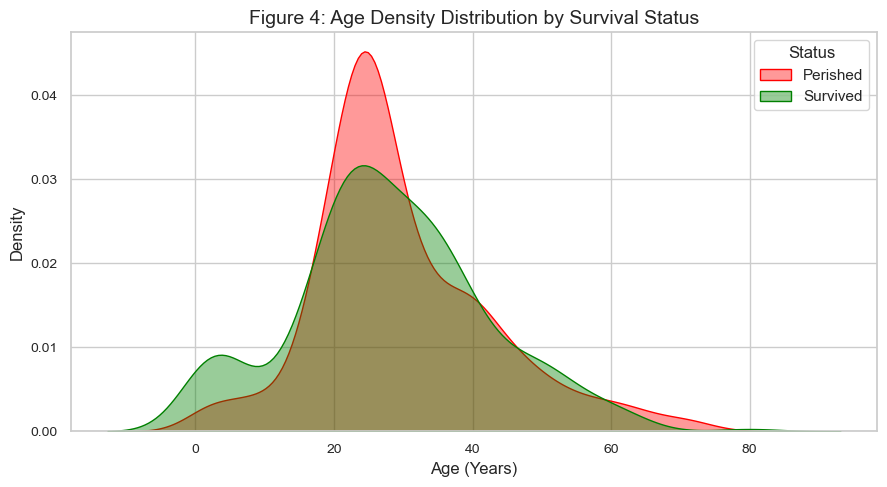

In [11]:
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df[df["Survived"] == 0]["Age"], label="Perished", fill=True, color="red", alpha=0.4)
sns.kdeplot(data=df[df["Survived"] == 1]["Age"], label="Survived", fill=True, color="green", alpha=0.4)
plt.title("Figure 4: Age Density Distribution by Survival Status")
plt.xlabel("Age (Years)")
plt.ylabel("Density")
plt.legend(title="Status")
plt.tight_layout()
plt.savefig("report/fig4_age_kde.png", dpi=300)
plt.show()


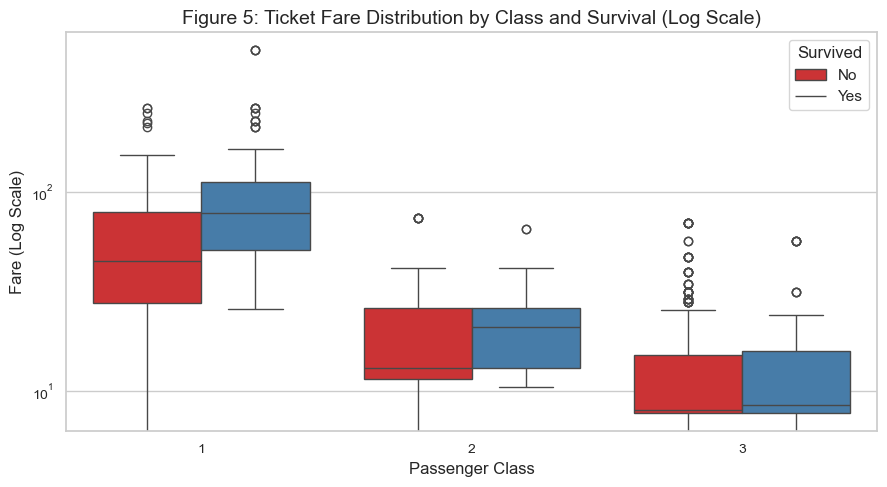

In [12]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Survived", palette="Set1")
plt.yscale("log")
plt.title("Figure 5: Ticket Fare Distribution by Class and Survival (Log Scale)")
plt.xlabel("Passenger Class")
plt.ylabel("Fare (Log Scale)")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()
plt.savefig("report/fig5_fare_boxplot.png", dpi=300)
plt.show()

## Correlation Heatmap & Export

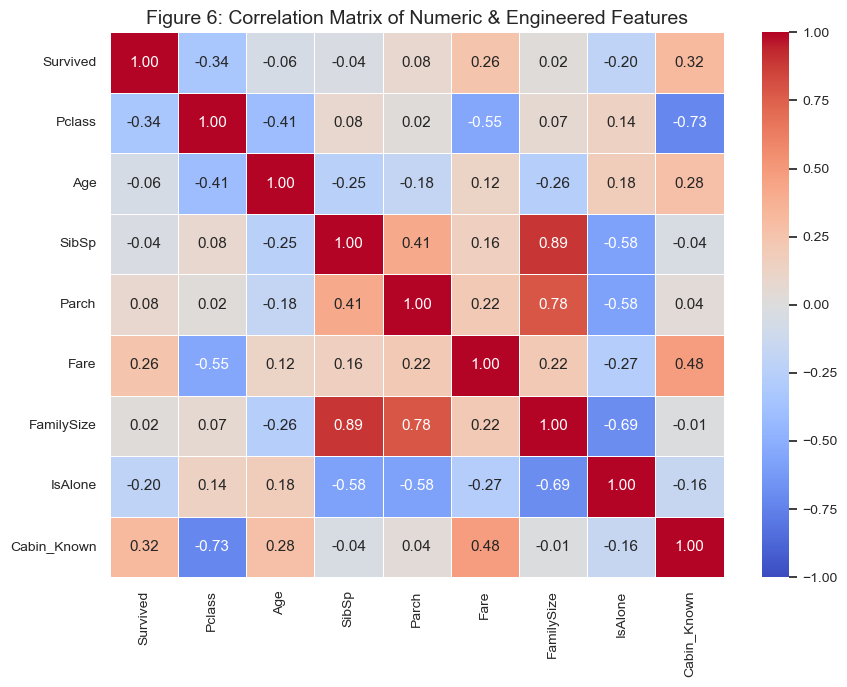

All 6 figures have been generated and saved directly into your 'notebooks/report/' folder!


In [14]:
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "Cabin_Known"]
corr_matrix = df[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Figure 6: Correlation Matrix of Numeric & Engineered Features")
plt.tight_layout()
plt.savefig("report/fig6_correlation_heatmap.png", dpi=300)
plt.show()
print("All 6 figures have been generated and saved directly into your 'notebooks/report/' folder!")